# Phase 1: real Nile precipitation input

Explore GPM_3IMERGM v07 monthly data for 2001-01 through 2024-12. This notebook validates source loading and conversion, and shows a monthly map plus one fixed cell. It does not estimate a trend or release inference. Product quality/error fields are retained; no new quality-index threshold is selected.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/architecture/scope.v2.json").exists())
sys.path.insert(0, str(root / "packages/science"))
from src.data_loader import input_entry, load_cube, monthly_precipitation_amount
entry = input_entry("precipitation", "nile_corridor", root=root)
ds = load_cube("precipitation", "nile_corridor", root=root)
rate = ds[entry["cube_variable"]]
amount = monthly_precipitation_amount(rate)
assert dict(ds.sizes) == {"time": 288, "lat": 80, "lon": 40}
print(json.dumps({"dimensions": dict(ds.sizes), "first_timestamp": str(ds.time.values[0]), "last_timestamp": str(ds.time.values[-1]), "source_units": rate.attrs["units"], "amount_units": amount.attrs["units"], "fields": list(ds.data_vars), "qa_status": ds.attrs["qa_status"]}, indent=2))

{
  "dimensions": {
    "time": 288,
    "lat": 80,
    "lon": 40
  },
  "first_timestamp": "2001-01-01T00:00:00.000000000",
  "last_timestamp": "2024-12-01T00:00:00.000000000",
  "source_units": "mm/hr",
  "amount_units": "mm",
  "fields": [
    "precipitation",
    "precipitationQualityIndex",
    "randomError"
  ],
  "qa_status": "ancillary fields retained; no additional product QA selection applied"
}


A mean rate in mm/hour must be multiplied by the actual number of hours in its calendar month. February 2004 has 29 days. The resulting values are monthly amounts in mm, not annual totals. Missing inputs remain missing.

In [2]:
np.testing.assert_allclose(amount.isel(time=0), rate.isel(time=0) * 31 * 24)
np.testing.assert_allclose(amount.isel(time=37), rate.isel(time=37) * 29 * 24)
qa_fields = {name: {"units": ds[name].attrs.get("units"), "missing_values": int(ds[name].isnull().sum())} for name in ["precipitationQualityIndex", "randomError"]}
print(json.dumps({"calendar_conversion_checks": "PASS", "ancillary_fields": qa_fields}, indent=2))

{
  "calendar_conversion_checks": "PASS",
  "ancillary_fields": {
    "precipitationQualityIndex": {
      "units": "1",
      "missing_values": 0
    },
    "randomError": {
      "units": "mm/hr",
      "missing_values": 0
    }
  }
}


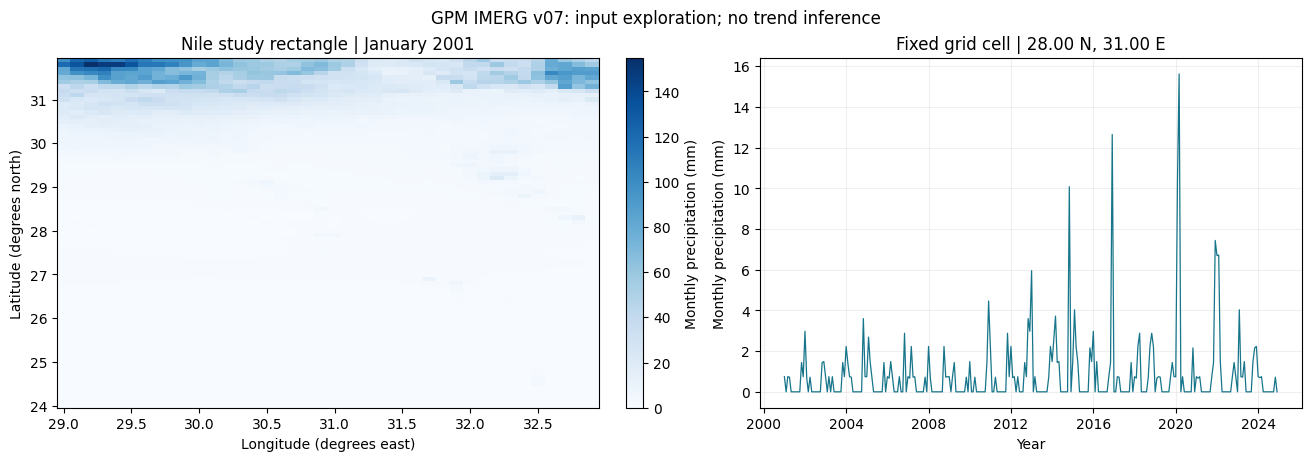

In [3]:
output = root / "data/derived/science/phase_1"
output.mkdir(parents=True, exist_ok=True)
lat_index, lon_index = ds.sizes["lat"] // 2, ds.sizes["lon"] // 2
cell = amount.isel(lat=lat_index, lon=lon_index)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
amount.isel(time=0).plot(ax=axes[0], x="lon", y="lat", cmap="Blues", cbar_kwargs={"label": "Monthly precipitation (mm)"})
axes[0].set_title("Nile study rectangle | January 2001")
axes[0].set_xlabel("Longitude (degrees east)")
axes[0].set_ylabel("Latitude (degrees north)")
axes[1].plot(cell.time.values, cell.values, color="#16758a", linewidth=0.9)
axes[1].set_title(f"Fixed grid cell | {float(cell.lat):.2f} N, {float(cell.lon):.2f} E")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Monthly precipitation (mm)")
axes[1].grid(alpha=0.2)
fig.suptitle("GPM IMERG v07: input exploration; no trend inference", fontsize=12)
fig.savefig(output / "precipitation_exploration.png", dpi=140)
display(fig)
plt.close(fig)

In [4]:
metadata = {
    "phase": "input_exploration_only",
    "variable_id": entry["variable_id"], "region_id": entry["region_id"],
    "product_id": entry["product_id"], "version": entry["version"],
    "source_variable": entry["source_variable"], "cube_variable": entry["cube_variable"],
    "source_url": "https://doi.org/10.5067/GPM/IMERG/3B-MONTH/07",
    "cube_file": entry["cube_file"],
    "cube_sha256": hashlib.sha256((root / entry["cube_file"]).read_bytes()).hexdigest(),
    "source_metadata": "data/nasa/expanded_v2/docs/GPM_3IMERGM_collection.json",
    "source_guide_manifest": "data/nasa/expanded_v2/docs/guide_sources.json",
    "dimensions": dict(ds.sizes), "period": entry["period"],
    "calendar": ds.time.encoding.get("calendar"),
    "source_units": rate.attrs["units"], "converted_units": amount.attrs["units"],
    "conversion": amount.attrs["conversion"],
    "source_fill_value": str(rate.encoding.get("_FillValue")),
    "missing_source_values": int(rate.isnull().sum()),
    "qa_status": ds.attrs["qa_status"], "ancillary_fields": qa_fields,
    "inference_status": "not_computed",
    "sample_cell": {"latitude": float(cell.lat), "longitude": float(cell.lon), "selection": "middle indices fixed before inspecting trends"},
    "plot": "data/derived/science/phase_1/precipitation_exploration.png",
}
metadata_path = root / "packages/science/phase_reports/PHASE_1_INPUT_METADATA.json"
metadata_path.write_text(json.dumps(metadata, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(metadata, indent=2))

{
  "phase": "input_exploration_only",
  "variable_id": "precipitation",
  "region_id": "nile_corridor",
  "product_id": "GPM_3IMERGM",
  "version": "07",
  "source_variable": "precipitation",
  "cube_variable": "precipitation",
  "source_url": "https://doi.org/10.5067/GPM/IMERG/3B-MONTH/07",
  "cube_file": "data/nasa/measurements/GPM_3IMERGM_Nile_2001_2024.nc",
  "cube_sha256": "967131aec4bdb0fa98ffc6ec9c9340cde164f5704be8f861c7ee02c130d6e219",
  "source_metadata": "data/nasa/expanded_v2/docs/GPM_3IMERGM_collection.json",
  "source_guide_manifest": "data/nasa/expanded_v2/docs/guide_sources.json",
  "dimensions": {
    "time": 288,
    "lat": 80,
    "lon": 40
  },
  "period": [
    "2001-01",
    "2024-12"
  ],
  "calendar": "proleptic_gregorian",
  "source_units": "mm/hr",
  "converted_units": "mm",
  "conversion": "monthly mean rate multiplied by Gregorian calendar-month days and 24 hours/day",
  "source_fill_value": "9.96921e+36",
  "missing_source_values": 0,
  "qa_status": "ancil

## Interpretation boundary

These plots describe the loaded input. They do not establish increasing/decreasing rainfall or its cause. Before regional or per-cell analysis, define spatial weights, valid support and coverage, product QA, and the annual/monthly estimand. Before inference, validate dependence-aware uncertainty and multiple testing. The existing annual-time-axis and spatial-minimum-length regressions remain open.